# **Análise exploratória dos dados**

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/home/joaoj/AC_project/data_analysis/training_data.csv")

# 5. Locais onde há sopro (só faz sentido para Present)
(df.loc[df["Murmur"] == "Present", "Murmur locations"].value_counts().head(10))

# 6. Demografia vs. classe
(df.groupby("Murmur")["Age"].value_counts().unstack(0))   # grupos etários
(pd.crosstab(df["Sex"], df["Murmur"], normalize="index").round(3))
(df.groupby("Murmur")[["Height", "Weight"]].describe().T)

# 7. Campanha (as duas campanhas podem ter distribuições diferentes)
(pd.crosstab(df["Campaign"], df["Murmur"]))

Murmur,Absent,Present,Unknown
Campaign,,,
CC2014,38,20,6
CC2015,12,13,3


### **Perceber o shape**

In [12]:
print(df.shape)
df.info()
print(df["Patient ID"].is_unique)

(93, 23)
<class 'pandas.DataFrame'>
RangeIndex: 93 entries, 0 to 92
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Patient ID                93 non-null     int64  
 1   Recording locations:      92 non-null     str    
 2   Age                       87 non-null     str    
 3   Sex                       92 non-null     str    
 4   Height                    85 non-null     float64
 5   Weight                    85 non-null     float64
 6   Pregnancy status          92 non-null     object 
 7   Murmur                    92 non-null     str    
 8   Murmur locations          33 non-null     str    
 9   Most audible location     33 non-null     str    
 10  Systolic murmur timing    33 non-null     str    
 11  Systolic murmur shape     33 non-null     str    
 12  Systolic murmur grading   33 non-null     str    
 13  Systolic murmur pitch     33 non-null     str    
 14  Systolic murmu

### **Gráfico de distribuição da classe alvo**

IMBALANCEEEEE

Murmur
Absent     50
Present    33
Unknown     9
Name: count, dtype: int64
Murmur
Absent     0.543
Present    0.359
Unknown    0.098
Name: proportion, dtype: float64


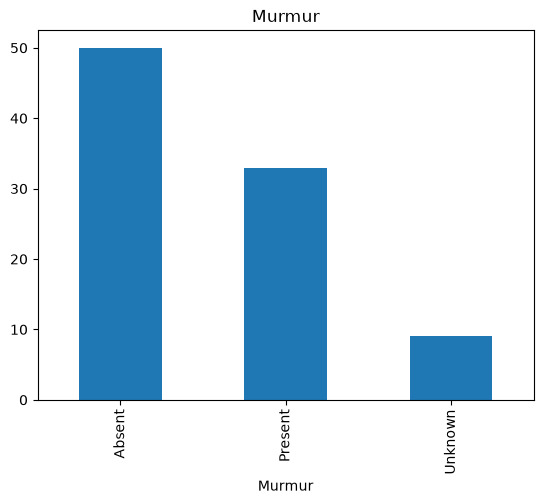

In [13]:
# 3. Distribuição da classe alvo (Murmur)
print(df["Murmur"].value_counts())
print(df["Murmur"].value_counts(normalize=True).round(3))
df["Murmur"].value_counts().plot(kind="bar", title="Murmur")
plt.show()

**Agrupar por doente**

In [14]:
# 4. Gravações por doente (a coluna lista os locais, ex.: "AV+PV+TV+MV")
df["n_rec_locais"] = df["Recording locations:"].str.split("+").str.len()
cr=pd.crosstab(df["n_rec_locais"], df["Murmur"])
print(df["n_rec_locais"].value_counts().sort_index())
cr


n_rec_locais
1.0     5
2.0    19
3.0     9
4.0    57
5.0     1
6.0     1
Name: count, dtype: int64


Murmur,Absent,Present,Unknown
n_rec_locais,,,
1.0,1,3,1
2.0,10,4,5
3.0,3,4,2
4.0,35,21,1
5.0,1,0,0
6.0,0,1,0


**Locais onde há sopro**

In [15]:
df.loc[df["Murmur"] == "Present", "Murmur locations"].value_counts().head(10)


Murmur locations
AV+MV+PV+TV    14
MV+PV+TV        5
MV              4
AV+MV           3
MV+TV           2
TV              1
MV+PV           1
AV+PV+TV        1
AV+MV+PV        1
AV+PV           1
Name: count, dtype: int64

In [16]:
df.isna().sum()

Patient ID                   0
Recording locations:         1
Age                          6
Sex                          1
Height                       8
Weight                       8
Pregnancy status             1
Murmur                       1
Murmur locations            60
Most audible location       60
Systolic murmur timing      60
Systolic murmur shape       60
Systolic murmur grading     60
Systolic murmur pitch       60
Systolic murmur quality     60
Diastolic murmur timing     91
Diastolic murmur shape      91
Diastolic murmur grading    91
Diastolic murmur pitch      91
Diastolic murmur quality    91
Outcome                      1
Campaign                     1
Additional ID               67
n_rec_locais                 1
dtype: int64

In [17]:
present = df[df["Murmur"] == "Present"].copy()
present["locs_sopro"] = present["Murmur locations"].str.split("+")
present["locs_gravados"] = present["Recording locations:"].str.split("+")
present

,Patient ID,Recording locations:,Age,Sex,Height,Weight,Pregnancy status,Murmur,Murmur locations,Most audible location,...,Diastolic murmur shape,Diastolic murmur grading,Diastolic murmur pitch,Diastolic murmur quality,Outcome,Campaign,Additional ID,n_rec_locais,locs_sopro,locs_gravados
1,9979,AV+PV+TV+MV,Child,Female,103.0,13.10,False,Present,AV+MV+PV+TV,TV,...,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN,4.0,"[AV, MV, PV, TV]","[AV, PV, TV, MV]"
3,13918,AV+PV+TV+MV,Child,Male,98.0,15.90,False,Present,TV,TV,...,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN,4.0,[TV],"[AV, PV, TV, MV]"
4,14241,AV+PV+TV+MV,Child,Male,87.0,11.20,False,Present,AV+MV+PV+TV,PV,...,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN,4.0,"[AV, MV, PV, TV]","[AV, PV, TV, MV]"
8,29045,AV+PV+TV+MV,Child,Female,88.0,12.50,False,Present,AV+MV+PV+TV,TV,...,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN,4.0,"[AV, MV, PV, TV]","[AV, PV, TV, MV]"
11,33151,AV+PV+TV+MV,Child,Female,141.0,30.90,False,Present,MV+TV,TV,...,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN,4.0,"[MV, TV]","[AV, PV, TV, MV]"
12,36327,AV+PV+TV+MV,Adolescent,Male,174.0,108.60,False,Present,MV+PV+TV,TV,...,NaN,NaN,NaN,NaN,Abnormal,CC2015,49630.0,4.0,"[MV, PV, TV]","[AV, PV, TV, MV]"
19,40840,AV+PV+TV+MV,Adolescent,Female,147.0,36.10,False,Present,AV+MV+PV+TV,PV,...,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN,4.0,"[AV, MV, PV, TV]","[AV, PV, TV, MV]"
21,44514,AV+PV+TV+MV,Adolescent,Male,152.0,39.50,False,Present,AV+MV+PV+TV,PV,...,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN,4.0,"[AV, MV, PV, TV]","[AV, PV, TV, MV]"
22,45843,AV+PV+TV+MV,Adolescent,Female,141.0,34.40,False,Present,MV+TV,MV,...,NaN,NaN,NaN,NaN,Abnormal,CC2015,49821.0,4.0,"[MV, TV]","[AV, PV, TV, MV]"
23,46065,AV+PV+TV+MV,Child,Male,111.0,18.30,False,Present,AV+MV+PV+TV,TV,...,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN,4.0,"[AV, MV, PV, TV]","[AV, PV, TV, MV]"


conclusões a retirar daqui: 
- 942 doentes
- class Murmur sem missing values
- Absent 695 (73,8%), Present 179 (19%), Unknown 68 (7,2%)
- cerca de 70 tem murmur presente nas 4 localizações


In [18]:
pd.crosstab(df["Campaign"], df["Murmur"], normalize="index").style.format("{:.1%}").background_gradient(cmap="Blues")

AttributeError: The '.style' accessor requires jinja2

In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display

DATA_DIR = Path("C:/Users/Maria/AC_project/data/data/circor/training_data")
wavs = pd.DataFrame({"file": [p.name for p in DATA_DIR.glob("*.wav")]})
wavs["patient_id"] = wavs["file"].str.split("_").str[0].astype(int)
print(len(wavs), "ficheiros .wav")          # esperado: 3163

# nº de ficheiros por doente
n_wav = wavs.groupby("patient_id").size().rename("n_wav")
d = df.merge(n_wav, left_on="Patient ID", right_index=True, how="left")
d["n_wav"] = d["n_wav"].fillna(0).astype(int)

# 1. Doentes no CSV sem nenhum áudio
sem_audio = d[d["n_wav"] == 0]
print(len(sem_audio), "doentes sem áudio")
display(sem_audio["Murmur"].value_counts())

# 2. O contrário: áudios de doentes que não estão no CSV
extra = set(wavs["patient_id"]) - set(df["Patient ID"])
print(len(extra), "IDs com áudio mas sem linha no CSV")

# 3. Locais listados no CSV vs. ficheiros existentes
display(pd.crosstab(d["n_rec_locais"], d["n_wav"]))